# v2 - 1. Prepare the data
Same cleaning rules as v1 (exact + near-duplicates, URL hosts repeated or in both classes, speaker tags removed), but a **new seed (2027)**: new sample of messages and safe calls, new 70/10/20 split, new pairing. The test file is written once, read-only and fingerprinted.

In [1]:
import os, sys
from pathlib import Path
os.environ["TOADWATCH_VERSION"] = "v2"          # selects the fair-fusion study (v2); keep this line first
sys.path.insert(0, str(Path.cwd().parent))       # notebooks live in ToadWatch_PR/notebooks
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
from toadwatch import config as C
from toadwatch import workflow as W
from toadwatch import reporting as R
print("version:", C.VERSION, "| seed:", C.SEED, "| outputs:", C.OUTPUTS_DIR)

version: v2 | seed: 2027 | outputs: /home/rush/Downloads/Fase/ToadWatch_PR/outputs/v2


In [2]:
out = W.prepare_data()      # ~2 minutes (streams the multi-GB files)
import json
print(json.dumps(out['calls_report'], indent=1, default=str))
print(json.dumps(out['msgs_report'], indent=1, default=str))

{
 "rows_raw": 8952,
 "unusable_rows": 54,
 "conflicting_label_rows": 0,
 "duplicate_rows": 1783,
 "near_duplicate_rows": 404,
 "rows_clean": 6711,
 "class_counts": {
  "0": 4666,
  "1": 2045
 }
}
{
 "rows_raw": 167759,
 "unusable_rows": 9,
 "url_duplicate_hosts": {
  "conflicting_label_rows": 516,
  "duplicate_rows": 45253
 },
 "text_duplicates": {
  "conflicting_label_rows": 0,
  "duplicate_rows": 973
 },
 "rows_clean": 120164,
 "counts_by_kind_label": {
  "email|0": 9644,
  "email|1": 9693,
  "sms|0": 8936,
  "sms|1": 1253,
  "url|0": 47347,
  "url|1": 43291
 }
}


In [3]:
pd.DataFrame(out['manifest']['files']).T

,rows,fraud,safe,sha256
train,2862,1432,1430,e217a0d4d2df39d873a0965aa5db61b58935d2a35f167a...
val,410,204,206,53947a4a780f775ea4bbfd1b85395ee4f69b81c49c38b1...
test,818,409,409,2c85baae319dd7453f9e3ece87ff51e6a1f148f62ab464...


## Leak checks (all must be True)

In [4]:
from toadwatch.cleaning import host_of, near_duplicate_share
from toadwatch.splitting import verify_test_untouched
rec = out["records"]; sp = {s: rec[rec.split == s] for s in ["train", "val", "test"]}
pairs = [("train","val"),("train","test"),("val","test")]
hosts = {s: set(d[d.msg_kind == "url"].msg_url.map(host_of)) for s, d in sp.items()}
print("call ids disjoint     :", all(not set(sp[a].call_id) & set(sp[b].call_id) for a, b in pairs))
print("message ids disjoint  :", all(not set(sp[a].item_id) & set(sp[b].item_id) for a, b in pairs))
print("URL hosts disjoint    :", all(not hosts[a] & hosts[b] for a, b in pairs))
print("call texts unique     :", rec.call_text.is_unique)
print("near-dup calls train->val:", round(near_duplicate_share(sp["train"].call_text, sp["val"].call_text), 3))
print("test fingerprint ok   :", verify_test_untouched())

call ids disjoint     : True
message ids disjoint  : True
URL hosts disjoint    : True
call texts unique     : True


near-dup calls train->val: 0.002
test fingerprint ok   : True


## Class and message-type balance
Every split is balanced by class, and every message type (SMS/email/URL) is balanced inside each class, so neither the class prior nor the message type can be used as a shortcut.

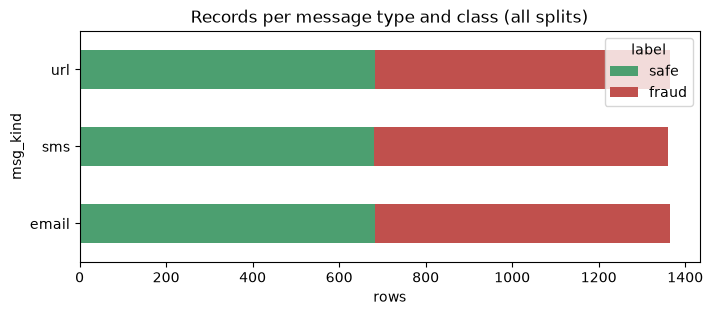

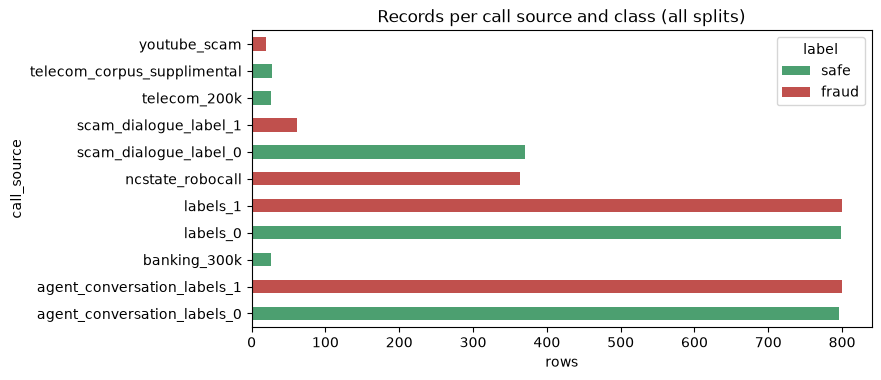

msg_kind     email  sms  url
split label                 
test  0        137  135  137
      1        137  135  137
train 0        477  476  477
      1        476  478  478
val   0         69   69   68
      1         68   68   68

In [5]:
R.plot_class_balance(rec, "msg_kind", "Records per message type and class (all splits)", "v2_00_balance_msgkind")
R.plot_class_balance(rec, "call_source", "Records per call source and class (all splits)", "v2_00_balance_callsource")
plt.show()
rec.groupby(["split", "label", "msg_kind"]).size().unstack(fill_value=0)